In [2]:
import sys
sys.path.append("..")

import torch
from torch.utils.data import DataLoader
from src.data.images import ProductImages, class_lists

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
groups, colours = class_lists()

train_ds = ProductImages("train")
val_ds = ProductImages("val")
print(f"Train: {len(train_ds):,} | Val: {len(val_ds):,}")

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=4, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=4, pin_memory=True)

x, yg, yc = next(iter(train_dl))
print("Batch images:", tuple(x.shape), "| group labels:", tuple(yg.shape), "| colour labels:", tuple(yc.shape))

Train: 74,295 | Val: 14,859
Batch images: (64, 3, 224, 224) | group labels: (64,) | colour labels: (64,)


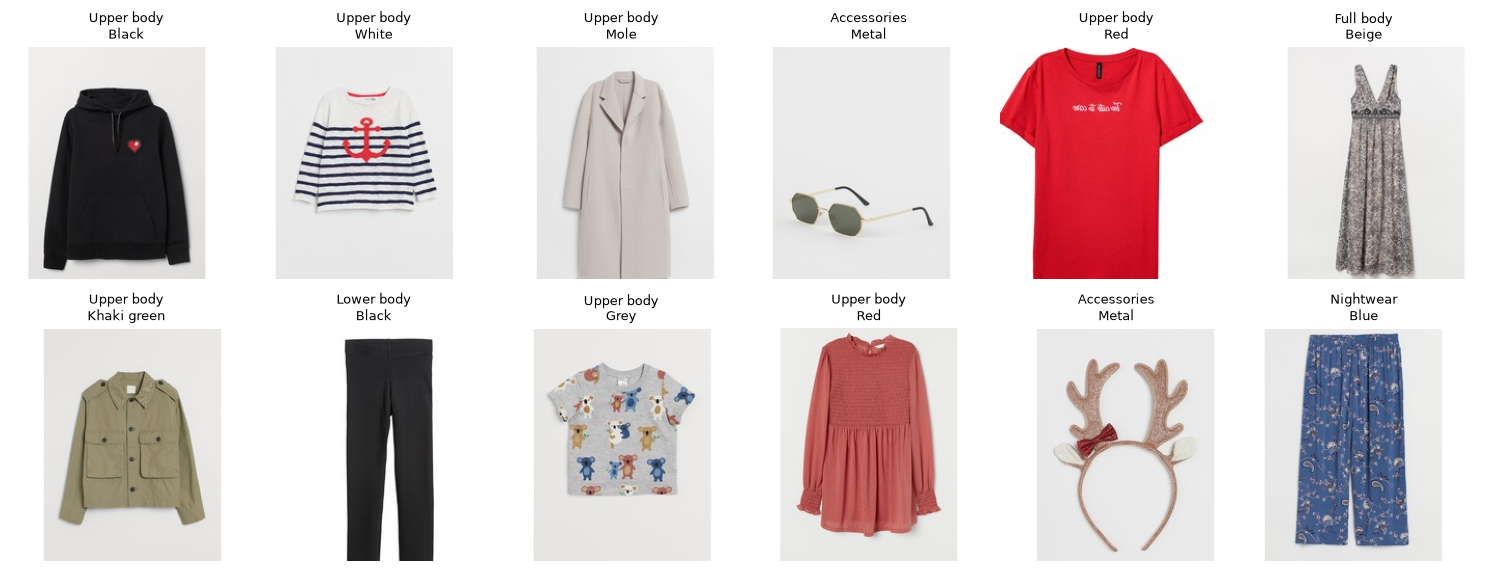

In [3]:
import matplotlib.pyplot as plt
from src.data.images import IMAGENET_MEAN, IMAGENET_STD

mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 6, figsize=(15, 6))
for ax, img, g, c in zip(axes.flat, x[:12], yg[:12], yc[:12]):
    shown = (img * std + mean).clamp(0, 1).permute(1, 2, 0)
    ax.imshow(shown)
    ax.set_title(f"{groups[g].replace('Garment ', '')}\n{colours[c]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
import copy
from torch import nn
from sklearn.metrics import f1_score, classification_report

data = torch.load("../data/processed/resnet50_features.pt")

F_tr = data["F_train"].float()
F_va = data["F_val"].float()
mean, std = F_tr.mean(dim=0), F_tr.std(dim=0) + 1e-6
F_tr = ((F_tr - mean) / std).to(device)
F_va = ((F_va - mean) / std).to(device)

G_tr, G_va = data["G_train"].to(device), data["G_val"].to(device)
C_tr, C_va = data["C_train"].to(device), data["C_val"].to(device)
print("Train:", tuple(F_tr.shape), "| Val:", tuple(F_va.shape))

Train: (74295, 2048) | Val: (14859, 2048)


In [5]:
def train_head(F_tr, y_tr, F_va, y_va, n_classes, epochs=60, patience=8, lr=0.01, batch_size=256):
    torch.manual_seed(42)
    head = nn.Linear(F_tr.shape[1], n_classes).to(device)      # the NEW final layer
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.SGD(head.parameters(), lr=lr, momentum=0.9)

    best_loss, bad = float("inf"), 0
    for epoch in range(1, epochs + 1):
        head.train()
        order = torch.randperm(len(F_tr), device=device)
        for i in range(0, len(F_tr), batch_size):
            idx = order[i:i + batch_size]
            loss = loss_fn(head(F_tr[idx]), y_tr[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()

        head.eval()
        with torch.no_grad():
            tr_loss = loss_fn(head(F_tr), y_tr).item()
            va_logits = head(F_va)
            va_loss = loss_fn(va_logits, y_va).item()
            va_acc = (va_logits.argmax(dim=1) == y_va).float().mean().item()
        print(f"epoch {epoch:2d} | train loss {tr_loss:.3f} | val loss {va_loss:.3f} | val acc {va_acc:.3f}")

        if va_loss < best_loss:
            best_loss, best_epoch, bad = va_loss, epoch, 0
            best_state = copy.deepcopy(head.state_dict())
        else:
            bad += 1
            if bad >= patience:
                print(f"No improvement for {patience} epochs, stopping.")
                break

    head.load_state_dict(best_state)
    print(f"Best epoch: {best_epoch} (val loss {best_loss:.3f})")
    return head


def report(head, F_va, y_va, names):
    with torch.no_grad():
        pred = head(F_va).argmax(dim=1).cpu().numpy()
    true = y_va.cpu().numpy()
    print(f"\nVal accuracy: {(pred == true).mean():.3f} | Val macro-F1: {f1_score(true, pred, average='macro'):.3f}\n")
    print(classification_report(true, pred, target_names=names, digits=3, zero_division=0))

In [6]:
group_head = train_head(F_tr, G_tr, F_va, G_va, n_classes=9)
report(group_head, F_va, G_va, groups)

epoch  1 | train loss 0.295 | val loss 0.370 | val acc 0.888
epoch  2 | train loss 0.254 | val loss 0.356 | val acc 0.891
epoch  3 | train loss 0.235 | val loss 0.355 | val acc 0.893
epoch  4 | train loss 0.222 | val loss 0.357 | val acc 0.892
epoch  5 | train loss 0.214 | val loss 0.359 | val acc 0.892
epoch  6 | train loss 0.208 | val loss 0.363 | val acc 0.893
epoch  7 | train loss 0.205 | val loss 0.368 | val acc 0.889
epoch  8 | train loss 0.198 | val loss 0.371 | val acc 0.890
epoch  9 | train loss 0.195 | val loss 0.373 | val acc 0.890
epoch 10 | train loss 0.191 | val loss 0.372 | val acc 0.892
epoch 11 | train loss 0.189 | val loss 0.376 | val acc 0.893
No improvement for 8 epochs, stopping.
Best epoch: 3 (val loss 0.355)

Val accuracy: 0.893 | Val macro-F1: 0.835

                    precision    recall  f1-score   support

       Accessories      0.920     0.942     0.931      1565
 Garment Full body      0.784     0.772     0.778      1881
Garment Lower body      0.924     

In [7]:
colour_head = train_head(F_tr, C_tr, F_va, C_va, n_classes=16)
report(colour_head, F_va, C_va, colours)

epoch  1 | train loss 0.895 | val loss 1.049 | val acc 0.697
epoch  2 | train loss 0.797 | val loss 1.007 | val acc 0.706
epoch  3 | train loss 0.755 | val loss 1.018 | val acc 0.705
epoch  4 | train loss 0.729 | val loss 1.008 | val acc 0.707
epoch  5 | train loss 0.708 | val loss 1.016 | val acc 0.706
epoch  6 | train loss 0.691 | val loss 1.029 | val acc 0.708
epoch  7 | train loss 0.683 | val loss 1.052 | val acc 0.706
epoch  8 | train loss 0.670 | val loss 1.056 | val acc 0.704
epoch  9 | train loss 0.664 | val loss 1.060 | val acc 0.706
epoch 10 | train loss 0.657 | val loss 1.075 | val acc 0.704
No improvement for 8 epochs, stopping.
Best epoch: 2 (val loss 1.007)

Val accuracy: 0.706 | Val macro-F1: 0.575

              precision    recall  f1-score   support

       Beige      0.557     0.571     0.564       809
       Black      0.777     0.880     0.826      3151
        Blue      0.771     0.806     0.789      2742
       Brown      0.611     0.527     0.566       334
     

In [8]:
torch.save(group_head.state_dict(), "../runs/frozen_group_head.pt")
torch.save(colour_head.state_dict(), "../runs/frozen_colour_head.pt")
print("Saved: runs/frozen_group_head.pt, runs/frozen_colour_head.pt")

Saved: runs/frozen_group_head.pt, runs/frozen_colour_head.pt
